## Импорты и настройки


In [1]:
import io
import random
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.datasets import load_digits
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split
from torchvision import datasets, models, transforms

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
SEED = 13
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"Device: {DEVICE}")


Device: cpu


## Общие функции обучения


In [2]:
def plot_history(history: dict[str, list[float]], title: str) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].plot(history["loss"], label="train")
    axes[0].plot(history["val_loss"], label="validation")
    axes[0].set_title(f"{title}: loss")
    axes[0].set_xlabel("epoch")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    axes[1].plot(history["acc"], label="train")
    axes[1].plot(history["val_acc"], label="validation")
    axes[1].set_title(f"{title}: accuracy")
    axes[1].set_xlabel("epoch")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def train_multiclass_epoch(model: nn.Module, loader: DataLoader, criterion: nn.Module, optimizer) -> tuple[float, float]:
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += float(loss.item()) * len(x)
        correct += int((logits.argmax(dim=1) == y).sum().item())
        total += len(x)
    return total_loss / total, correct / total


def evaluate_multiclass(model: nn.Module, loader: DataLoader, criterion: nn.Module) -> tuple[float, float]:
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            total_loss += float(criterion(logits, y).item()) * len(x)
            correct += int((logits.argmax(dim=1) == y).sum().item())
            total += len(x)
    return total_loss / total, correct / total


def train_binary_epoch(model: nn.Module, loader: DataLoader, criterion: nn.Module, optimizer) -> tuple[float, float]:
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for x, y in loader:
        x = x.to(DEVICE)
        y = y.float().to(DEVICE)
        optimizer.zero_grad()
        logits = model(x).view(-1)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += float(loss.item()) * len(x)
        correct += int(((torch.sigmoid(logits) >= 0.5).float() == y).sum().item())
        total += len(x)
    return total_loss / total, correct / total


def evaluate_binary(model: nn.Module, loader: DataLoader, criterion: nn.Module) -> tuple[float, float]:
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)
            y = y.float().to(DEVICE)
            logits = model(x).view(-1)
            total_loss += float(criterion(logits, y).item()) * len(x)
            correct += int(((torch.sigmoid(logits) >= 0.5).float() == y).sum().item())
            total += len(x)
    return total_loss / total, correct / total


## Этап 1. CNN для MNIST


In [3]:
class MnistCnn(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 7 * 7, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 10),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x))


In [ ]:
mnist_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])

try:
    mnist_train_full = datasets.MNIST("data", train=True, download=True, transform=mnist_transform)
    mnist_test = datasets.MNIST("data", train=False, download=True, transform=mnist_transform)
    mnist_source = "MNIST"
except Exception:
    digits = load_digits()
    x_digits = torch.tensor(digits.images[:, None, :, :], dtype=torch.float32) / 16.0
    x_digits = F.interpolate(x_digits, size=(28, 28), mode="bilinear", align_corners=False)
    x_digits = (x_digits - 0.1307) / 0.3081
    y_digits = torch.tensor(digits.target, dtype=torch.long)
    full_digits = TensorDataset(x_digits, y_digits)
    train_size = int(0.8 * len(full_digits))
    test_size = len(full_digits) - train_size
    mnist_train_full, mnist_test = random_split(
        full_digits, [train_size, test_size], generator=torch.Generator().manual_seed(SEED)
    )
    mnist_source = "sklearn digits fallback"

val_size = max(1, int(0.1 * len(mnist_train_full)))
train_size = len(mnist_train_full) - val_size
mnist_train, mnist_val = random_split(
    mnist_train_full, [train_size, val_size], generator=torch.Generator().manual_seed(SEED)
)

mnist_train_loader = DataLoader(mnist_train, batch_size=128, shuffle=True, num_workers=0)
mnist_val_loader = DataLoader(mnist_val, batch_size=256, shuffle=False, num_workers=0)
mnist_test_loader = DataLoader(mnist_test, batch_size=256, shuffle=False, num_workers=0)

print(f"Dataset: {mnist_source}")
print(f"Train/val/test sizes: {len(mnist_train)}/{len(mnist_val)}/{len(mnist_test)}")


epoch 01: loss=1.6224, acc=0.4158, val_acc=0.9161
epoch 02: loss=0.2935, acc=0.9080, val_acc=0.9580
epoch 03: loss=0.1368, acc=0.9544, val_acc=0.9790
epoch 04: loss=0.0963, acc=0.9714, val_acc=0.9790
epoch 05: loss=0.0512, acc=0.9853, val_acc=0.9860
epoch 06: loss=0.0432, acc=0.9869, val_acc=0.9790
epoch 07: loss=0.0231, acc=0.9915, val_acc=0.9790
epoch 08: loss=0.0220, acc=0.9915, val_acc=0.9580
epoch 09: loss=0.0124, acc=0.9954, val_acc=0.9790
epoch 10: loss=0.0114, acc=0.9977, val_acc=0.9860
epoch 11: loss=0.0097, acc=0.9961, val_acc=0.9790
epoch 12: loss=0.0337, acc=0.9884, val_acc=0.9860
epoch 13: loss=0.0244, acc=0.9907, val_acc=0.9510
epoch 14: loss=0.0268, acc=0.9907, val_acc=0.9720
epoch 15: loss=0.0146, acc=0.9954, val_acc=0.9720
epoch 16: loss=0.0084, acc=0.9969, val_acc=0.9860
epoch 17: loss=0.0063, acc=0.9985, val_acc=0.9790
epoch 18: loss=0.0102, acc=0.9985, val_acc=0.9790
epoch 19: loss=0.0019, acc=1.0000, val_acc=0.9790
epoch 20: loss=0.0006, acc=1.0000, val_acc=0.9860


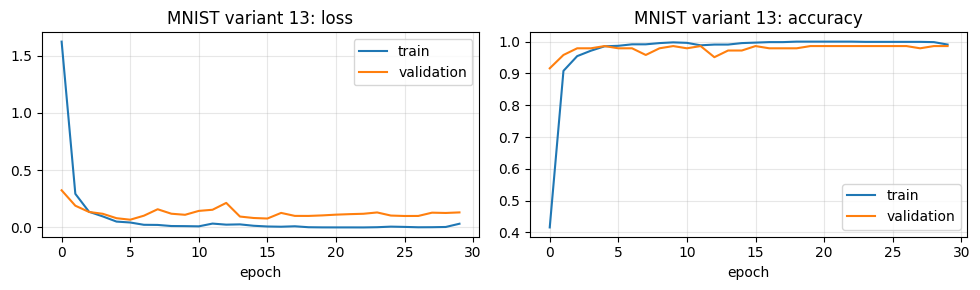

In [5]:
mnist_model = MnistCnn().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mnist_model.parameters(), lr=1e-3)

MNIST_EPOCHS = 30
mnist_history = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
for epoch in range(MNIST_EPOCHS):
    loss, acc = train_multiclass_epoch(mnist_model, mnist_train_loader, criterion, optimizer)
    val_loss, val_acc = evaluate_multiclass(mnist_model, mnist_val_loader, criterion)
    mnist_history["loss"].append(loss)
    mnist_history["acc"].append(acc)
    mnist_history["val_loss"].append(val_loss)
    mnist_history["val_acc"].append(val_acc)
    print(f"epoch {epoch + 1:02d}: loss={loss:.4f}, acc={acc:.4f}, val_acc={val_acc:.4f}")

mnist_test_loss, mnist_test_acc = evaluate_multiclass(mnist_model, mnist_test_loader, criterion)
print(f"MNIST test_loss={mnist_test_loss:.4f}, test_acc={mnist_test_acc:.4f}")
plot_history(mnist_history, "MNIST variant 13")


### Baseline

epoch 01: loss=1.8634, acc=0.5386, val_acc=0.8741
epoch 02: loss=0.5619, acc=0.8501, val_acc=0.8462
epoch 03: loss=0.3097, acc=0.8957, val_acc=0.8671
epoch 04: loss=0.2382, acc=0.9250, val_acc=0.9161
epoch 05: loss=0.1766, acc=0.9366, val_acc=0.9510
epoch 06: loss=0.1223, acc=0.9652, val_acc=0.9441
epoch 07: loss=0.0945, acc=0.9753, val_acc=0.9510
epoch 08: loss=0.1275, acc=0.9560, val_acc=0.9441
epoch 09: loss=0.1674, acc=0.9436, val_acc=0.9580
epoch 10: loss=0.1187, acc=0.9598, val_acc=0.9790
epoch 11: loss=0.0678, acc=0.9784, val_acc=0.9650
epoch 12: loss=0.0463, acc=0.9869, val_acc=0.9790
epoch 13: loss=0.0444, acc=0.9876, val_acc=0.9650
epoch 14: loss=0.0350, acc=0.9907, val_acc=0.9441
epoch 15: loss=0.0349, acc=0.9900, val_acc=0.9790
epoch 16: loss=0.0221, acc=0.9977, val_acc=0.9860
epoch 17: loss=0.0132, acc=0.9985, val_acc=0.9860
epoch 18: loss=0.0105, acc=0.9992, val_acc=0.9860
epoch 19: loss=0.0086, acc=0.9992, val_acc=0.9860
epoch 20: loss=0.0081, acc=1.0000, val_acc=0.9860


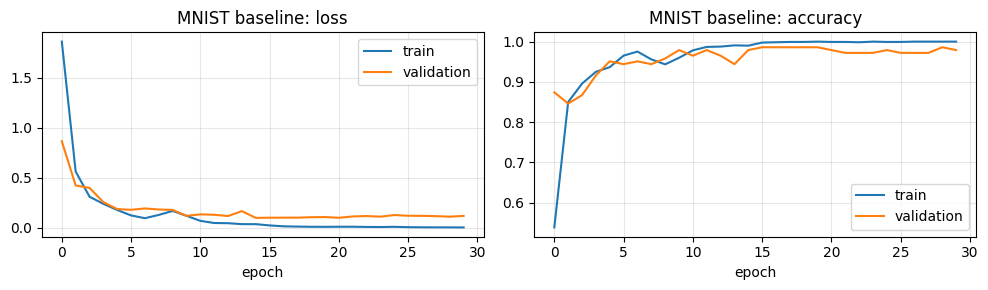


Сопоставление с базовой сетью:
  вариант 13 (64-128-128-256, 1x512): test_acc=0.9944
  baseline   (32-64,          1x64):  test_acc=0.9833
  разница: +0.0111


In [6]:
class MnistBaselineCnn(nn.Module):
    """Базовая сеть из задания: 2 слоя 32-64, ядро 3x3, классификатор 1 слой (64)."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x))


baseline_model = MnistBaselineCnn().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=1e-3)

BASELINE_EPOCHS = 30
baseline_history = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
for epoch in range(BASELINE_EPOCHS):
    loss, acc = train_multiclass_epoch(baseline_model, mnist_train_loader, criterion, optimizer)
    val_loss, val_acc = evaluate_multiclass(baseline_model, mnist_val_loader, criterion)
    baseline_history["loss"].append(loss)
    baseline_history["acc"].append(acc)
    baseline_history["val_loss"].append(val_loss)
    baseline_history["val_acc"].append(val_acc)
    print(f"epoch {epoch + 1:02d}: loss={loss:.4f}, acc={acc:.4f}, val_acc={val_acc:.4f}")

baseline_test_loss, baseline_test_acc = evaluate_multiclass(baseline_model, mnist_test_loader, criterion)
print(f"Baseline test_loss={baseline_test_loss:.4f}, test_acc={baseline_test_acc:.4f}")
plot_history(baseline_history, "MNIST baseline")

print("\nСопоставление с базовой сетью:")
print(f"  вариант 13 (64-128-128-256, 1x512): test_acc={mnist_test_acc:.4f}")
print(f"  baseline   (32-64,          1x64):  test_acc={baseline_test_acc:.4f}")
print(f"  разница: {mnist_test_acc - baseline_test_acc:+.4f}")

## Этап 2. Cats vs Dogs на малом объеме данных


In [ ]:
class CatsDogsZipDataset(Dataset):
    """Читает изображения из архива один раз и держит их в памяти.

    Однократное декодирование (вместо открытия архива на каждом обращении)
    кардинально ускоряет обучение: на каждой эпохе используются уже готовые
    изображения, а zip-архив больше не переоткрывается.
    """

    def __init__(self, zip_path: Path, image_size: int, max_per_class: int = 700, normalize: bool = False):
        if not zip_path.exists():
            raise FileNotFoundError(f"Не найден архив Cats vs Dogs: {zip_path}")
        self.normalize = normalize
        self.to_tensor = transforms.ToTensor()
        self.normalizer = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        resize = transforms.Resize((image_size, image_size))

        with zipfile.ZipFile(zip_path) as archive:
            cat_names = [n for n in archive.namelist() if n.startswith("PetImages/Cat/") and n.lower().endswith(".jpg")]
            dog_names = [n for n in archive.namelist() if n.startswith("PetImages/Dog/") and n.lower().endswith(".jpg")]
            random.Random(SEED).shuffle(cat_names)
            random.Random(SEED).shuffle(dog_names)
            samples = [(name, 0) for name in cat_names[:max_per_class]] + [(name, 1) for name in dog_names[:max_per_class]]
            random.Random(SEED).shuffle(samples)

            self.images: list[np.ndarray] = []
            self.labels: list[int] = []
            for name, label in samples:
                try:
                    image = Image.open(io.BytesIO(archive.read(name))).convert("RGB")
                except Exception:
                    continue  # пропускаем повреждённые файлы из набора
                self.images.append(np.asarray(resize(image), dtype=np.uint8))
                self.labels.append(label)

    def __len__(self) -> int:
        return len(self.images)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        image = self.to_tensor(self.images[index])
        if self.normalize:
            image = self.normalizer(image)
        return image, torch.tensor(float(self.labels[index]), dtype=torch.float32)


class SmallBinaryCnn(nn.Module):
    def __init__(self, channels: list[int], image_size: int, hidden: int):
        super().__init__()
        blocks = []
        in_channels = 3
        size = image_size
        for out_channels in channels:
            blocks.extend([
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.MaxPool2d(2),
            ])
            in_channels = out_channels
            size //= 2
        self.features = nn.Sequential(*blocks)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels[-1] * size * size, hidden),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(hidden, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x))


In [ ]:
cats_dataset = CatsDogsZipDataset(Path("../Cats vs Dogs/kagglecatsanddogs_3367a.zip"), image_size=200, max_per_class=700)
train_size = int(0.7 * len(cats_dataset))
val_size = int(0.15 * len(cats_dataset))
test_size = len(cats_dataset) - train_size - val_size
cats_train, cats_val, cats_test = random_split(
    cats_dataset, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(SEED)
)

cats_train_loader = DataLoader(cats_train, batch_size=32, shuffle=True, num_workers=0)
cats_val_loader = DataLoader(cats_val, batch_size=64, shuffle=False, num_workers=0)
cats_test_loader = DataLoader(cats_test, batch_size=64, shuffle=False, num_workers=0)

x_preview, y_preview = next(iter(cats_train_loader))
fig, axes = plt.subplots(1, 6, figsize=(12, 2))
for ax, image, label in zip(axes, x_preview[:6], y_preview[:6]):
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title("dog" if int(label.item()) == 1 else "cat")
    ax.axis("off")
plt.tight_layout()
plt.show()

print(f"Cats vs Dogs sizes: {len(cats_train)}/{len(cats_val)}/{len(cats_test)}")


In [ ]:
cats_model = SmallBinaryCnn([32, 64, 64, 128], image_size=200, hidden=256).to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(cats_model.parameters(), lr=1e-3)

CATS_EPOCHS = 30
cats_history = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
for epoch in range(CATS_EPOCHS):
    loss, acc = train_binary_epoch(cats_model, cats_train_loader, criterion, optimizer)
    val_loss, val_acc = evaluate_binary(cats_model, cats_val_loader, criterion)
    cats_history["loss"].append(loss)
    cats_history["acc"].append(acc)
    cats_history["val_loss"].append(val_loss)
    cats_history["val_acc"].append(val_acc)
    print(f"epoch {epoch + 1:02d}: loss={loss:.4f}, acc={acc:.4f}, val_acc={val_acc:.4f}")

cats_test_loss, cats_test_acc = evaluate_binary(cats_model, cats_test_loader, criterion)
print(f"Cats vs Dogs test_loss={cats_test_loss:.4f}, test_acc={cats_test_acc:.4f}")
plot_history(cats_history, "Cats vs Dogs variant 13")


## Этап 3. Transfer learning

Сверточная основа замораживается, обучается только новый бинарный классификатор.


In [ ]:
class TransferCatsDogsDataset(CatsDogsZipDataset):
    def __init__(self, zip_path: Path, max_per_class: int = 700):
        # Размер 224x224 и нормализация по статистикам ImageNet для ResNet18.
        super().__init__(zip_path, image_size=224, max_per_class=max_per_class, normalize=True)


transfer_dataset = TransferCatsDogsDataset(Path("../Cats vs Dogs/kagglecatsanddogs_3367a.zip"), max_per_class=700)
train_size = int(0.7 * len(transfer_dataset))
val_size = int(0.15 * len(transfer_dataset))
test_size = len(transfer_dataset) - train_size - val_size
transfer_train, transfer_val, transfer_test = random_split(
    transfer_dataset, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(SEED)
)

transfer_train_loader = DataLoader(transfer_train, batch_size=32, shuffle=True, num_workers=0)
transfer_val_loader = DataLoader(transfer_val, batch_size=64, shuffle=False, num_workers=0)
transfer_test_loader = DataLoader(transfer_test, batch_size=64, shuffle=False, num_workers=0)


In [ ]:
try:
    weights = models.ResNet18_Weights.DEFAULT
    transfer_model = models.resnet18(weights=weights)
    print("Loaded pretrained ResNet18 weights")
except Exception as exc:
    transfer_model = models.resnet18(weights=None)
    print(f"Pretrained weights are unavailable locally, architecture is created without them: {exc}")

for parameter in transfer_model.parameters():
    parameter.requires_grad = False

transfer_model.fc = nn.Sequential(
    nn.Linear(transfer_model.fc.in_features, 256),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(256, 1),
)
transfer_model = transfer_model.to(DEVICE)

trainable = sum(p.numel() for p in transfer_model.parameters() if p.requires_grad)
print(f"Trainable parameters: {trainable}")


In [ ]:
criterion = nn.BCEWithLogitsLoss()

# Сверточная основа ResNet18 заморожена, поэтому её выход (признаки) не меняется
# в процессе обучения. Вычислим признаки один раз и далее обучаем только
# классификатор на этих признаках — это многократно ускоряет обучение и полностью
# соответствует варианту (заморозка основы, обучение только классификатора).
classifier_head = transfer_model.fc
transfer_model.fc = nn.Identity()
transfer_model.eval()


def extract_features(loader: DataLoader) -> tuple[torch.Tensor, torch.Tensor]:
    features, targets = [], []
    with torch.no_grad():
        for x, y in loader:
            features.append(transfer_model(x.to(DEVICE)).cpu())
            targets.append(y)
    return torch.cat(features), torch.cat(targets)


train_features, train_targets = extract_features(transfer_train_loader)
val_features, val_targets = extract_features(transfer_val_loader)
test_features, test_targets = extract_features(transfer_test_loader)
transfer_model.fc = classifier_head  # вернуть классификатор на место

feature_train_loader = DataLoader(TensorDataset(train_features, train_targets), batch_size=32, shuffle=True)
feature_val_loader = DataLoader(TensorDataset(val_features, val_targets), batch_size=64, shuffle=False)
feature_test_loader = DataLoader(TensorDataset(test_features, test_targets), batch_size=64, shuffle=False)

classifier = classifier_head.to(DEVICE)
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

TRANSFER_EPOCHS = 70
transfer_history = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
for epoch in range(TRANSFER_EPOCHS):
    loss, acc = train_binary_epoch(classifier, feature_train_loader, criterion, optimizer)
    val_loss, val_acc = evaluate_binary(classifier, feature_val_loader, criterion)
    transfer_history["loss"].append(loss)
    transfer_history["acc"].append(acc)
    transfer_history["val_loss"].append(val_loss)
    transfer_history["val_acc"].append(val_acc)
    print(f"epoch {epoch + 1:02d}: loss={loss:.4f}, acc={acc:.4f}, val_acc={val_acc:.4f}")

transfer_test_loss, transfer_test_acc = evaluate_binary(classifier, feature_test_loader, criterion)
print(f"Transfer test_loss={transfer_test_loss:.4f}, test_acc={transfer_test_acc:.4f}")
plot_history(transfer_history, "Transfer learning")


baseline доделать